# Домашнее задание 3. Логистическая регрессия и Streamlit

## Описание

В этом задании вы реализуете логистическую регрессию своими руками, разберётесь с метриками качества классификации на реальных несбалансированных данных и упакуете итоговую модель в интерактивное веб-приложение на Streamlit.

- Первая часть посвящена реализации логистической регрессии с помощью градиентного и стохастического градиентного спуска.
- Вторая часть посвящена метрикам классификации: матрице ошибок, precision, recall, $F_\beta$, ROC- и PR-кривым, выбору порога.
- Третья часть посвящена работе с несбалансированными классами.
- Четвертая часть посвящена созданию демонстрации на Streamlit.

**Максимальный балл за задание: 10** (по 2.5 балла за каждую из четырёх частей).

## Общие требования к ДЗ-3

- Для каждого задания приведите код решения.
- Там, где требуется интерпретация, добавьте короткий текстовый вывод.
- Следите за тем, чтобы ноутбук выполнялся последовательно сверху вниз.
- Везде, где есть случайность, фиксируйте `random_state=42`.
- Тестовая выборка используется **только** для финальной оценки качества. Всё, что «подбирается» (гиперпараметры, порог, ресемплинг, параметры масштабирования), подбирается по тренировочной выборке.

> В каждой части оцениваются как код, так и ответы на вопросы. Если отсутствует одно из двух, часть баллов за соответствующее задание может быть снижена.

In [1]:
%pip install imbalanced-learn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn import metrics
from scipy.special import log_expit

sns.set_style('darkgrid')
RANDOM_STATE = 42

## <font color="green">Часть 1. Логистическая регрессия своими руками (2.5 балла)</font>

На лекции мы получили функцию потерь логистической регрессии из метода максимума правдоподобия. Если $p_i = \sigma(\langle w, x_i \rangle)$ – предсказанная вероятность класса 1 для $i$-го объекта, то

$$Q(w) = -\frac{1}{\ell}\sum_{i=1}^{\ell}\Big(y_i \log p_i + (1 - y_i)\log(1 - p_i)\Big) \to \min_w, \qquad \sigma(z) = \frac{1}{1 + e^{-z}}.$$

Явной формулы для минимума, как у МНК, здесь нет, поэтому веса ищем градиентным спуском – так же, как на семинаре 3 для линейной регрессии.

**Подсказка.** Сначала выведите градиент $\nabla Q(w)$ на бумаге и запишите его в матричном виде через $X$, $y$ и вектор вероятностей $p$. Вывод градиента приводить в ноутбуке не обязательно, но на защите его могут попросить.

### Задание 1.1. Класс `LogReg` (1.5 балла)

Реализуйте класс логистической регрессии, обучаемой с помощью:
- **полного градиентного спуска** – `gd_type='full'` (1 балл);
- **стохастического градиентного спуска** – `gd_type='stochastic'`: на каждой итерации градиент оценивается по случайному батчу из `batch_size` объектов, как в функции `calc_grad_on_batch` с семинара 3 (0.5 балла).

**Требования:**
- Градиентный спуск записан в векторном виде. Циклы средствами Python допускаются **только** по итерациям градиентного спуска.
- Свободный член $w_0$ учитывается так, как на лекции: внутри `fit` и `predict_proba` к матрице признаков добавляется фиктивный признак $x_0 = 1$ (первым столбцом). Таким образом, `self.w` имеет размер `d + 1`, и `self.w[0]` – это свободный член.
- Критерии остановки (одновременно):
  - L2 норма разности весов на двух соседних итерациях меньше `tolerance`;
  - достигнуто максимальное число итераций `max_iter`.
- Атрибут `loss_history` после вызова `fit` содержит значение функции потерь **на всей обучающей выборке** для каждой итерации, начиная с первой (до совершения первого шага по антиградиенту).
- Веса инициализируются вектором `w0`, если он передан, иначе – нулевым вектором.
- `predict_proba` возвращает массив размера `(N, 2)`: в первом столбце вероятность класса 0, во втором – класса 1 (как в `sklearn`).
- `predict` возвращает метки классов `0/1`, сравнивая вероятность класса 1 с порогом `threshold`.
- При вычислении логарифма в `calc_loss` позаботьтесь о вычислительной устойчивости: $\log 0$ давать не должно (например, используйте `np.clip`).

Полезно [почитать](https://scikit-learn.org/stable/developers/develop.html) о том, как устроены модели в `sklearn`.

**ВАЖНО!** Заполните шаблон ниже, не меняя структуру класса и сигнатуры методов. Добавлять свои вспомогательные методы можно.

In [3]:
class LogReg(BaseEstimator, ClassifierMixin):
    def __init__(self, gd_type='full', tolerance=1e-4, max_iter=1000,
                 w0=None, eta=1e-2, batch_size=32, random_state=42):
        """
        gd_type: 'full' или 'stochastic'
        tolerance: порог для критерия останова по норме разности весов
        max_iter: максимальное число итераций градиентного спуска
        w0: np.array размера (d + 1) — начальные веса (w0[0] — свободный член)
        eta: длина шага (learning rate)
        batch_size: размер батча для стохастического градиентного спуска
        random_state: seed для выбора батчей
        """
        self.gd_type = gd_type
        self.tolerance = tolerance
        self.max_iter = max_iter
        self.w0 = w0
        self.eta = eta
        self.batch_size = batch_size
        self.random_state = random_state

    def fit(self, X, y):
        """
        X: np.array размера (N, d)
        y: np.array размера (N) из 0 и 1
        ---
        output: self
        """
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        self.classes_ = np.array([0, 1])
        self.loss_history = []
        rng = np.random.default_rng(self.random_state)

        # ваше решение здесь
        X = np.hstack([np.ones((X.shape[0], 1)), X])
        if self.w0 is None:
          self.w = np.zeros(X.shape[1])
        else:
          self.w = np.array(self.w0, dtype=float).copy()

        for _ in range(self.max_iter):
          self.loss_history.append(self.calc_loss(X, y))
          if self.gd_type == 'full':
            grad = self.calc_gradient(X, y)
          elif self.gd_type == 'stochastic':
            idx = rng.choice(X.shape[0], size=self.batch_size, replace=False)
            grad = self.calc_gradient(X[idx], y[idx])
          else:
            raise ValueError("неизвестный gd_type")

          newW = self.w - self.eta * grad
          dif = np.linalg.norm(newW - self.w)
          self.w = newW
          if self.tolerance is not None and dif < self.tolerance:
            break

        return self

    def sigmoid(self, z):
        # ваше решение здесь
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))

    def predict_proba(self, X):
        """
        X: np.array размера (N, d)
        ---
        output: np.array размера (N, 2)
        """
        if getattr(self, 'w', None) is None:
            raise Exception('Not trained yet')

        # ваше решение здесь
        X = np.asarray(X, dtype=float)
        X = np.hstack([np.ones((X.shape[0], 1)), X])
        p = self.sigmoid(X @ self.w)
        return np.column_stack([1 - p, p])

    def predict(self, X, threshold=0.5):
        """
        X: np.array размера (N, d)
        ---
        output: np.array размера (N) из 0 и 1
        """
        if getattr(self, 'w', None) is None:
            raise Exception('Not trained yet')

        # ваше решение здесь
        p = self.predict_proba(X)[:, 1]
        return (p >= threshold).astype(int)

    def calc_gradient(self, X, y):
        """
        X: np.array размера (N, d + 1) — уже с фиктивным признаком
           (N может быть равно batch_size при стохастическом спуске)
        y: np.array размера (N)
        ---
        output: np.array размера (d + 1) — градиент log-loss по self.w
        """
        # ваше решение здесь
        p = self.sigmoid(X @ self.w)
        return X.T @ (p - y) / len(y)

    def calc_loss(self, X, y):
        """
        X: np.array размера (N, d + 1) — уже с фиктивным признаком
        y: np.array размера (N)
        ---
        output: float — значение log-loss при текущих self.w
        """
        # ваше решение здесь
        z = X @ self.w
        logP = log_expit(z)
        log1_P = log_expit(-z)
        loss = -np.mean(y * logP + (1 - y) * log1_P)
        return float(loss)

Ячейка ниже проверяет вашу реализацию градиента численно: сравнивает `calc_gradient` с конечными разностями функции `calc_loss`. Она не оценивается, но если проверка не проходит – ищите ошибку, прежде чем идти дальше.

In [4]:
def check_gradient(model, d=5, N=50, eps=1e-6, seed=0):
    rng = np.random.default_rng(seed)
    X = np.hstack([np.ones((N, 1)), rng.normal(size=(N, d))])
    y = rng.integers(0, 2, size=N).astype(float)
    model.w = rng.normal(size=d + 1)

    analytic = model.calc_gradient(X, y)
    numeric = np.zeros(d + 1)
    w = model.w.copy()
    for j in range(d + 1):
        e = np.zeros(d + 1)
        e[j] = eps
        model.w = w + e
        loss_plus = model.calc_loss(X, y)
        model.w = w - e
        loss_minus = model.calc_loss(X, y)
        numeric[j] = (loss_plus - loss_minus) / (2 * eps)
    model.w = w
    return np.max(np.abs(analytic - numeric))


err = check_gradient(LogReg())
print(f'max |analytic - numeric| = {err:.2e}')
assert err < 1e-5, 'Градиент не совпадает с численным — проверьте calc_gradient и calc_loss'

max |analytic - numeric| = 1.17e-10


Теперь проверим работу класса на синтетических данных.

In [5]:
X, y = make_classification(
    n_samples=20000, n_features=20, n_informative=5,
    random_state=RANDOM_STATE)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE)

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

### Задание 1.2. Обучение и сходимость (0.25 балла)

1. Обучите две модели: `LogReg(gd_type='full')` и `LogReg(gd_type='stochastic')` с параметрами по умолчанию.
2. Для каждой модели выведите число сделанных итераций и постройте на одном графике `loss_history` обеих моделей.
3. Ответьте на вопросы:
   - По какому критерию остановилась каждая модель – по `tolerance` или по `max_iter`?
   - Почему стохастическому спуску с постоянным шагом трудно остановиться по критерию `tolerance`?
   - Чем отличаются графики функции потерь?
   - Сколько объектов «просматривает» за одну итерацию каждый из методов?

GD: 1000 итераций
SGD: 1000 итераций


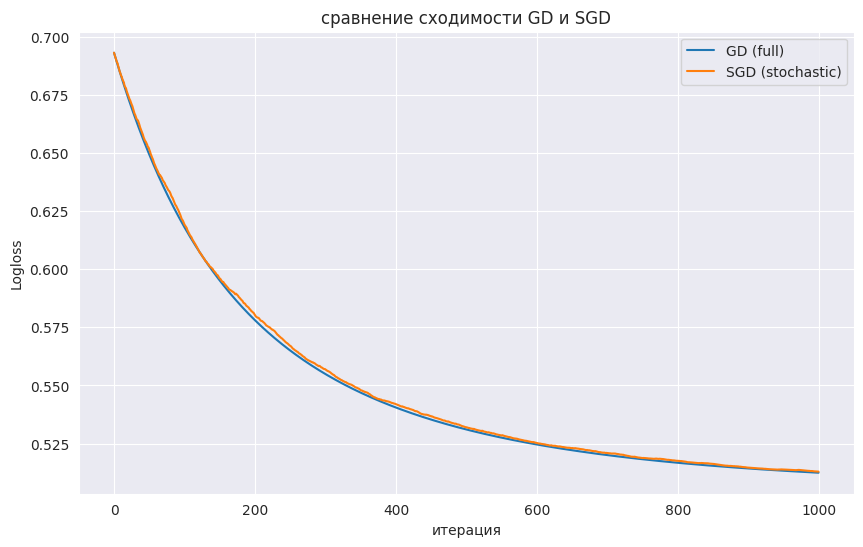

In [6]:
# ваше решение здесь
model1 = LogReg(gd_type='full')
model1.fit(X_train, y_train)
model2 = LogReg(gd_type='stochastic')
model2.fit(X_train, y_train)
print(f"GD: {len(model1.loss_history)} итераций")
print(f"SGD: {len(model2.loss_history)} итераций")
plt.figure(figsize=(10, 6))
plt.plot(model1.loss_history, label='GD (full)')
plt.plot(model2.loss_history, label='SGD (stochastic)')
plt.xlabel('итерация')
plt.ylabel('Logloss')
plt.title('сравнение сходимости GD и SGD')
plt.legend()
plt.grid(True)
plt.show()

*Ваши выводы здесь.*

- обе модели остановились по max_iter=1000, тк tolerance=1e-4 не был выполнен
- sgd трудно остановиться по tolerance, тк градиент вычисляется по случайному батчу и имеет шум, даже вблизи мин веса продолжают колебаться, поэтому норма их изменения не обязательно становится достаточно маленькой
- обе модели постепенно уменьшают log loss примерно с 0.69 до 0.51. кривая gd более гладкая, а у sgd есть небольшие колебания из за случайного выбора батчей, но графики почти совпадают, то есть у методов сопоставимая сходимость по итерациям
- за одну итерацию gd использует все 14000 обучающих объектов для вычисления градиента, а sgd только 32 + функция потерь в обоих случаях допом вычисляется на всем треине

### Задание 1.3. Длина шага (0.25 балла)

Для полного градиентного спуска обучите модели с сеткой `eta` из списка `[1e-3, 1e-2, 1e-1, 1, 10]` и постройте графики `loss_history` (удобно в логарифмической шкале по оси `x`). Выведите для каждого `eta` финальное значение функции потерь и число итераций.

Как длина шага влияет на скорость и качество сходимости? Есть ли значения `eta`, при которых спуск ведёт себя плохо?

eta = 0.001
итераций = 1000
финальный лосс = 0.6180873957343579

eta = 0.01
итераций = 1000
финальный лосс = 0.5124349858596444

eta = 0.1
итераций = 465
финальный лосс = 0.5057619732437159

eta = 1
итераций = 70
финальный лосс = 0.5057566598343406

eta = 10
итераций = 1000
финальный лосс = 0.9013447927456616



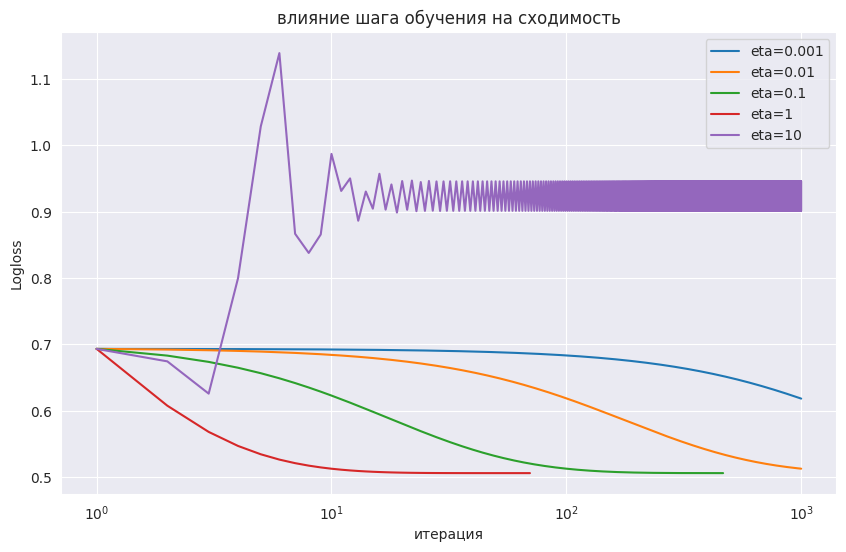

In [7]:
# ваше решение здесь
etaList = [1e-3, 1e-2, 1e-1, 1, 10]
results = {}
plt.figure(figsize=(10, 6))
for eta in etaList:
  model = LogReg(gd_type='full', eta=eta)
  model.fit(X_train, y_train)
  results[eta] = model
  XWithOnes = np.hstack([np.ones((X_train.shape[0], 1)), X_train])
  finalLoss = model.calc_loss(XWithOnes, y_train)
  print(f"eta = {eta}")
  print(f"итераций = {len(model.loss_history)}")
  print(f"финальный лосс = {finalLoss}\n")
  plt.plot(np.arange(1, len(model.loss_history) + 1), model.loss_history, label=f'eta={eta}')

plt.xscale('log')
plt.xlabel('итерация')
plt.ylabel('Logloss')
plt.title('влияние шага обучения на сходимость')
plt.legend()
plt.grid(True)
plt.show()

*Ваши выводы здесь.*

- с увеличением eta от 0.001 до 1 скорость сходимости gd растет. при маленьких шагах 0.001 и 0.01 gd не успевает сойтись за 1000 итераций, а при 0.1 достигает критерия останова за 465 итераций, при 1 за 70 итераций. лучший шаг - eta = 1, при котором финальный log loss - 0.50576

- но при слишком большом шаге eta = 10 gd начинает перескакивать через область мин, из за чего функция потерь сильно колеблется и не сходится. финальный log loss - около 0.901, что даже выше начального значения. то есть, слишком маленький шаг замедляет сходимость, а слишком большой может сделать её нестабильной

### Задание 1.4. Сравнение с `sklearn` (0.5 балла)

1. Обучите `LogisticRegression` из `sklearn` с параметрами по умолчанию.
2. Для трёх моделей (ваш GD, ваш SGD, `sklearn`) посчитайте на тестовой выборке accuracy и ROC-AUC и сведите их в таблицу `pd.DataFrame`.
3. Сравните веса вашей модели (GD) с весами модели `sklearn` (`intercept_` и `coef_`).

Ответьте на вопросы:
   - Совпадают ли метрики? Совпадают ли веса?
   - Что в модели `sklearn` по умолчанию делает её не равной вашей? Найдите ответ в [документации](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html). Как настроить `LogisticRegression`, чтобы она решала ту же задачу оптимизации, что и ваша модель?

In [8]:
# ваше решение здесь
modelSklearn = LogisticRegression()
modelSklearn.fit(X_train, y_train)
models = {'GD': model1, 'SGD': model2, 'sklearn': modelSklearn}
res = []
for name, model in models.items():
  yPred = model.predict(X_test)
  yPredProba = model.predict_proba(X_test)[:, 1]
  res.append({'модель': name, 'accuracy': metrics.accuracy_score(y_test, yPred), 'roc-auc': metrics.roc_auc_score(y_test, yPredProba)})

dfRes = pd.DataFrame(res)
display(dfRes)
sklearnW = np.r_[modelSklearn.intercept_, modelSklearn.coef_.ravel()]
dfW = pd.DataFrame({'признак': ['intercept'] + [f'x{i}' for i in range(X_train.shape[1])], 'GD': model1.w, 'sklearn': sklearnW})
display(dfW)

,модель,accuracy,roc-auc
0,GD,0.7820,0.838787
1,SGD,0.7825,0.838115
2,sklearn,0.7765,0.838676


,признак,GD,sklearn
0,intercept,-0.002114,-0.021880
1,x0,0.006076,0.002741
2,x1,0.006963,0.009039
3,x2,-0.547170,-0.722690
4,x3,-0.144536,-0.262335
5,x4,0.012487,0.016588
6,x5,-0.006325,-0.011488
7,x6,0.000814,0.005587
8,x7,0.039084,0.057188
9,x8,-0.002425,-0.001239


*Ваши выводы здесь.*

- метрики трёх моделей близки, но не совпадают, accuracy - 0.782 у gd, 0.7825 у sgd и 0.7765 у sklearn. roc-auc тоже почти совпадает: 0.838787 у gd, 0.838115 у sgd и 0.838676 у sklearn

- веса gd и sklearn различаются, хотя их знаки совпадают. это потому что LogisticRegression из sklearn по умолчанию использует l2 регуляризацию с C=1, а моя модель минимизирует log loss без регуляризации + sklearn использует оптимизатор L-BFGS, а мой gd за 1000 итераций ещё не достиг критерия сходимости

- чтобы sklearn решала ту же задачу оптимизации, надо выключить регуляризацию, поставив penalty=None (или C=np.inf в новых версиях). для более точного совпадения весов надо еще обеспечить достаточную сходимость обеих моделей

## <font color="green">Часть 2. Метрики классификации (2.5 балла)</font>

### Данные

Используем датасет [Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality) (P. Cortez et al., 2009, лицензия CC BY 4.0).
Каждая строка – образец португальского вина: 11 физико-химических характеристик и признак `is_red` (1 - красное, 0 - белое). Эксперты оценили каждое вино по шкале от 0 до 10. Мы превратили оценку в бинарную целевую переменную:

- `target = 1` – «хорошее» вино (оценка не ниже 7);
- `target = 0` – все остальные.

**Сценарий.** Сервис по подписке каждый месяц рекомендует клиентам вина. Модель должна по результатам лабораторного анализа отбирать «хорошие» вина в подборку. Рекомендовать клиенту посредственное вино — плохо (клиент разочаруется), но и пропускать хорошие вина тоже не хочется (подборка получится скудной).

In [9]:
df = pd.read_csv('https://raw.githubusercontent.com/paiflare/ml_hse_2026/refs/heads/master/homework/hw_3/Data/wine_quality.csv')

print('Data shape:', df.shape)
df.head()

Data shape: (6497, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,is_red,target
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,1,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,1,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,1,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0


In [10]:
X = df.drop(columns='target')
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)

print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (4547, 12)  Test: (1950, 12)


### Задание 2.1. Первичный анализ и accuracy (0.25 балла)

1. Проверьте данные на пропуски и полные дубликаты строк. Нужно ли удалять дубликаты в этой задаче? Посчитайте долю класса 1 (prevalence) в тренировочной и тестовой выборках. Зачем при разбиении был указан параметр `stratify=y`?
2. Посчитайте accuracy на тестовой выборке для константной модели, которая всегда отвечает «не хорошее вино» (класс 0).
3. Обучите пайплайн `make_pipeline(StandardScaler(), LogisticRegression())` и посчитайте его accuracy на тестовой выборке.

Сравните два числа. Почему accuracy плохо подходит для этой задачи?

In [11]:
# ваше решение здесь
print(f"колво пропусков: {df.isna().sum()}")
print(f"колво полных дубликатов: {df.duplicated().sum()}")
print(f"доля класса 1 на треине: {y_train.mean()}")
print(f"доля класса 1 на тесте: {y_test.mean()}")
yZeros = np.zeros(len(y_test), dtype=int)
accurZ = metrics.accuracy_score(y_test, yZeros)
print(f"accuracy константной модели: {accurZ}")
pipel = make_pipeline(StandardScaler(), LogisticRegression())
pipel.fit(X_train, y_train)
yPred = pipel.predict(X_test)
accurPip = metrics.accuracy_score(y_test, yPred)
print(f"accuracy пайплайна: {accurPip}")

колво пропусков: fixed_acidity           0
volatile_acidity        0
citric_acid             0
residual_sugar          0
chlorides               0
free_sulfur_dioxide     0
total_sulfur_dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
is_red                  0
target                  0
dtype: int64
колво полных дубликатов: 1177
доля класса 1 на треине: 0.19661315152848033
доля класса 1 на тесте: 0.19641025641025642
accuracy константной модели: 0.8035897435897436
accuracy пайплайна: 0.82


*Ваши выводы здесь.*

- в данных нет пропусков, но есть 1177 полных дубликатов. удалять их не обязательно, тк одинаковые характеристики могут соответствовать разным образцам вина, но если это повторные записи одних объектов, то они могут завышать оценку качества при попадании одновременно в треин и тест

- доля класса 1 - 19.66% на треине и 19.64% на тесте. stratify=y помог сохранить примерно одинаковые пропорции классов в обеих выборках

- accuracy константной модели - 0.8036, а логистической регрессии — 0.82. то есть, логистическая регрессия улучшила accuracy всего на 0.0164

- accuracy плохо подходит для этой задачи из за дисбаланса классов, тк константная модель показывает высокую долю верных ответов, хотя не обнаруживает ни одного хорошего вина. для сервиса рекомендаций важно учитывать как колво найденных хороших вин, так и долю действительно хороших среди рекомендованных, поэтому надо допом использовать precision и recall

### Задание 2.2. Матрица ошибок своими руками (0.5 балла)

Для пайплайна логистической регрессии из задания 2.1 получите предсказания классов на тестовой выборке.

1. Посчитайте TP, TN, FP, FN **без функций из `sklearn.metrics`** – только средствами `numpy`/`pandas`.
2. Сравните результат с `metrics.confusion_matrix` и нарисуйте матрицу ошибок с помощью `metrics.ConfusionMatrixDisplay`.
3. Объясните в терминах сценария, что означают FP и FN в этой задаче. Какая из ошибок модели встречается чаще?

 TP: 98
 TN: 1501
 FP: 66
 FN: 285

матрица ошибок:
[[1501   66]
 [ 285   98]]


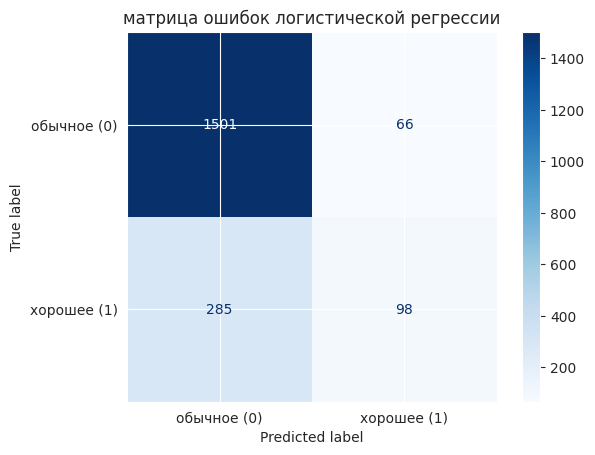

In [12]:
# ваше решение здесь
tp = np.sum((y_test == 1) & (yPred == 1))
tn = np.sum((y_test == 0) & (yPred == 0))
fp = np.sum((y_test == 0) & (yPred == 1))
fn = np.sum((y_test == 1) & (yPred == 0))
print(f" TP: {tp}\n TN: {tn}\n FP: {fp}\n FN: {fn}")
matr = metrics.confusion_matrix(y_test, yPred)
print("\nматрица ошибок:")
print(matr)
assert np.array_equal(matr, [[tn, fp], [fn, tp]])
metrics.ConfusionMatrixDisplay(confusion_matrix=matr, display_labels=['обычное (0)', 'хорошее (1)']).plot(cmap='Blues')
plt.title('матрица ошибок логистической регрессии')
plt.show()

*Ваши выводы здесь.*

- результаты без функции из sklearn.metrics совпадают с результатми metrics.confusion_matrix

- FP = 66 — модель ошибочно рекомендует обычное вино как хорошее, что может привести к разочарованию клиента

- FN = 285 — модель не рекомендует действительно хорошее вино, из за чего сервис не предлагает клиенту качественное вино, то есть они зарабатывают меньше

- ошибки FN встречаются чаще, чем FP (285 против 66). Из 383 хороших вин модель правильно обнаружила только 98, то есть около 25.6%, пропустив остальные

- то есть, несмотря на accuracy = 0.82, модель плохо обнаруживает хорошие вина. это потому что accuracy сильно зависит от качества предсказаний нулевого класса, которого больше, и не показывает отдельно качество обнаружения класса 1

### Задание 2.3. Precision, recall, $F_\beta$ (0.5 балла)

1. Используя TP, TN, FP, FN из задания 2.2, посчитайте по формулам precision, recall, $F_1$, $F_{0.5}$ и $F_2$:

$$F_{\beta} = (1 + \beta^2)\frac{\text{Precision} \cdot \text{Recall}}{\beta^2 \cdot \text{Precision} + \text{Recall}}.$$

2. Проверьте свои значения с помощью `metrics.precision_score`, `metrics.recall_score`, `metrics.fbeta_score`.
3. Ответьте на вопросы:
   - Что больше ценится в $F_{0.5}$, а что в $F_2$ – precision или recall?
   - Какую из трёх F-мер вы бы выбрали для нашего сценария, если подписчики очень болезненно реагируют на посредственные вина в подборке? А если сервис позиционирует себя как «самая широкая подборка хороших вин»?

In [13]:
# ваше решение здесь
precision = tp / (tp + fp)
recall = tp / (tp + fn)
def fBeta(precision, recall, beta):
  return (1 + beta ** 2) * precision * recall / (beta ** 2 * precision + recall)

f1 = fBeta(precision, recall, 1)
f05 = fBeta(precision, recall, 0.5)
f2 = fBeta(precision, recall, 2)
print(f"precision: {precision}")
print(f"recall: {recall}")
print(f"f1: {f1}")
print(f"f0.5: {f05}")
print(f"f2: {f2}")
print("\nпроверка через sklearn metrics")
print(f"precision: {metrics.precision_score(y_test, yPred)}")
print(f"recall: {metrics.recall_score(y_test, yPred)}")
print(f"f1: {metrics.fbeta_score(y_test, yPred, beta=1)}")
print(f"f0.5: {metrics.fbeta_score(y_test, yPred, beta=0.5)}")
print(f"f2: {metrics.fbeta_score(y_test, yPred, beta=2)}")

precision: 0.5975609756097561
recall: 0.2558746736292428
f1: 0.35831809872029247
f0.5: 0.47160731472569783
f2: 0.28891509433962265

проверка через sklearn metrics
precision: 0.5975609756097561
recall: 0.2558746736292428
f1: 0.3583180987202925
f0.5: 0.4716073147256978
f2: 0.28891509433962265


*Ваши выводы здесь.*

- precision = 0.5976, recall = 0.2559, F1 = 0.3583, F0.5 = 0.4716, F2 = 0.2889, все значения по формулам совпали со sklearn.metrics

- в f0.5 больший приоритет отдаётся precision, а в f2 recall. f1 учитывает обе метрики с одинаковой важностью

- если подписчики болезненно реагируют на посредственные вина, лучше выбрать F0.5, тк важно уменьшить количество FP и увеличить долю действительно хороших вин среди рекомендованных

- если сервис позиционируется как «самая широкая подборка хороших вин», то лучше выбрать f2, тк важно уменьшить количество FN и находить как можно больше хороших вин, даже если при этом несколько снизится precision

### Задание 2.4. ROC- и PR-кривые (0.5 балла)

Сравним две модели:
- `make_pipeline(StandardScaler(), LogisticRegression())` из `sklearn`;
- ваш `LogReg(gd_type='full')` из части 1 (не забудьте масштабировать признаки, подберите `eta` и `max_iter` так, чтобы спуск сошёлся).

1. Для каждой модели получите на тестовой выборке **непрерывные оценки** (score) – вероятность класса 1.
2. Постройте ROC-кривые двух моделей на одном графике и PR-кривые двух моделей на другом графике. На PR-графике отметьте горизонтальной линией уровень случайной модели.
3. Посчитайте ROC-AUC (`metrics.roc_auc_score`) и PR-AUC (`metrics.average_precision_score`) и сведите в таблицу.
4. Возьмите вероятности $p$ класса 1 модели из `sklearn` и посчитайте ROC-AUC для преобразованных оценок: $10 \cdot p$, $p^3$, $\log\frac{p}{1-p}$, $-p$. Объясните результат.

Ответьте на вопросы:
- Какая модель лучше? Совпадает ли ранжирование моделей по ROC-AUC и по PR-AUC?
- Чему равен PR-AUC случайной модели в этой задаче и почему он не равен 0.5?
- Что получится, если подать в `roc_auc_score` предсказанные метки классов?

итераций: 2554
последний сохраненный лосс: 0.3917234976077933


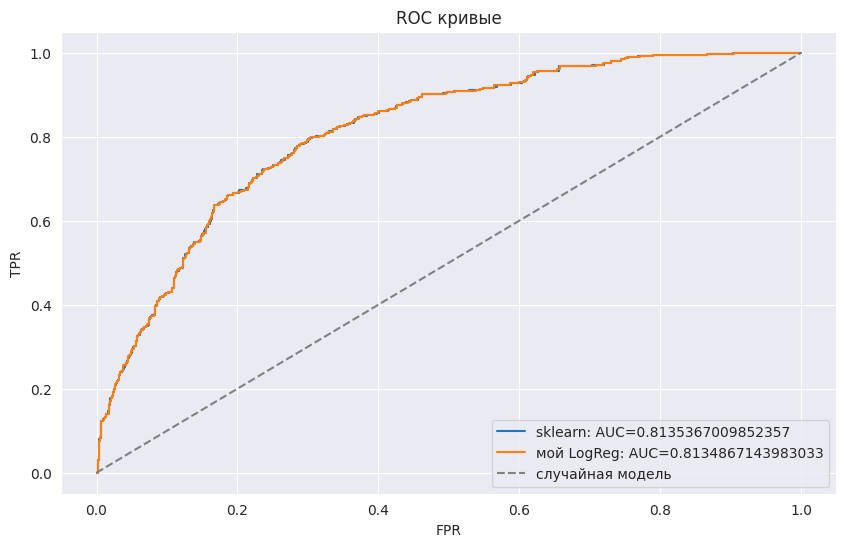

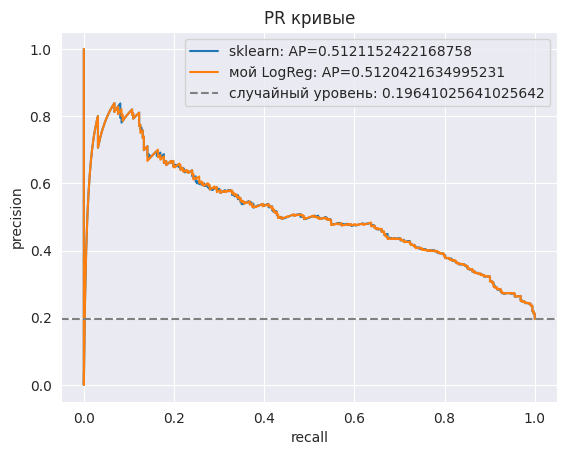

,модель,roc-auc,pr-auc
0,sklearn,0.813537,0.512115
1,мой LogReg,0.813487,0.512042


p: roc-auc = 0.8135367009852357
10 * p: roc-auc = 0.8135367009852357
p ** 3: roc-auc = 0.8134867143983033
log(p / (1 - p)): roc-auc = 0.8135367009852357
-p: roc-auc = 0.18646329901476436
roc-auc по вероятностям: 0.8135367009852357
roc-auc по меткам классов: 0.6068779877399565


In [14]:
# ваше решение здесь
scaler24 = StandardScaler()
XTrainScaled24 = scaler24.fit_transform(X_train)
XTestScaled24 = scaler24.transform(X_test)
model24 = LogReg(gd_type='full', eta=0.5, max_iter=5000)
model24.fit(XTrainScaled24, y_train)
print(f"итераций: {len(model24.loss_history)}")
print(f"последний сохраненный лосс: {model24.loss_history[-1]}")
pSk = pipel.predict_proba(X_test)[:, 1]
p24 = model24.predict_proba(XTestScaled24)[:, 1]
scores = {'sklearn': pSk, 'мой LogReg': p24}
plt.figure(figsize=(10, 6))
for name, p in scores.items():
  fpr, tpr, thresholds = metrics.roc_curve(y_test, p)
  auc = metrics.roc_auc_score(y_test, p)
  plt.plot(fpr, tpr, label=f'{name}: AUC={auc}')

plt.plot([0, 1], [0, 1], '--', color='gray', label='случайная модель')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.title('ROC кривые')
plt.legend()
plt.grid(True)
plt.show()
for name, p in scores.items():
  prec, rec, thresholds = metrics.precision_recall_curve(y_test, p)
  ap = metrics.average_precision_score(y_test, p)
  plt.plot(rec, prec, label=f'{name}: AP={ap}')

plt.axhline(y_test.mean(), linestyle='--', color='gray', label=f'случайный уровень: {y_test.mean()}')
plt.xlabel('recall')
plt.ylabel('precision')
plt.title('PR кривые')
plt.legend()
plt.grid(True)
plt.show()
results24 = []
for name, p in scores.items():
  results24.append({'модель': name, 'roc-auc': metrics.roc_auc_score(y_test, p), 'pr-auc': metrics.average_precision_score(y_test, p)})

dfRes24 = pd.DataFrame(results24)
display(dfRes24)
pSkSafe = np.clip(pSk, 1e-15, 1 - 1e-15)
transf = {'p': pSk, '10 * p': 10 * pSk, 'p ** 3': p ** 3, 'log(p / (1 - p))': np.log(pSkSafe / (1 - pSkSafe)), '-p': -pSk}
for name, vals in transf.items():
  auc = metrics.roc_auc_score(y_test, vals)
  print(f"{name}: roc-auc = {auc}")

aucProba = metrics.roc_auc_score(y_test, pipel.predict_proba(X_test)[:, 1])
aucClass = metrics.roc_auc_score(y_test, pipel.predict(X_test))
print(f"roc-auc по вероятностям: {aucProba}")
print(f"roc-auc по меткам классов: {aucClass}")

*Ваши выводы здесь.*

- при преобразованиях 10p, p ** 3 и log(p/(1-p)) ROC-AUC не изменяется и остаётся 0.813537, тк эти преобразования сохраняют порядок объектов по предсказанной оценке, а при -p порядок меняется на противоположный, поэтому roc-auc становится 1 - 0.813537 = 0.186463

- по roc-auc и pr-auc немного лучше sklearn, тк roc-auc = 0.813537 и pr-auc = 0.512115 против 0.813487 и 0.512042 у моей LogReg, но различия очень маленькие, поэтому модели показывают почти одинаковое качество. ранжирование моделей по обеим метрикам совпадает

- случайный уровень PR кривой примерно равен 0.1964, тк доля положительного класса в тесте равна 19.64%. в отличие от roc-auc, где случайный уровень - 0.5, базовый уровень PR кривой зависит от распространённости положительного класса


- если передать в roc_auc_score предсказанные метки классов вместо вероятностей,то метрика по нашим данным будет примерно 0.6069, что связано с потерей информации о ранжировании, то есть вместо непрерывных оценок остаются только 0 и 1

### Задание 2.5. Выбор порога (0.75 балла)

Порог 0.5 у логистической регрессии ничем не выделен – его можно и нужно выбирать под задачу. Но подбирать порог на тестовой выборке нельзя: тогда оценка качества на тесте окажется завышенной.

1. Выделите из тренировочной выборки валидационную (`test_size=0.25`, `stratify`, `random_state=42`). Обучите пайплайн логистической регрессии на оставшейся части и получите вероятности на валидации.
2. Постройте на одном графике зависимость precision, recall и $F_1$ на валидации от порога $t \in [0, 1]$.
3. По валидации выберите два порога:
   - $t_{F_1}$ – максимизирующий $F_1$;
   - $t_{R}$ – дающий максимальный precision при условии recall $\ge 0.7$ (сервис хочет, чтобы в подборку попадало не меньше 70% хороших вин).
4. Переобучите пайплайн на всей тренировочной выборке и посчитайте на тестовой выборке precision, recall и $F_1$ при порогах $0.5$, $t_{F_1}$ и $t_{R}$. Сведите результаты в таблицу.

Выполнилось ли на тесте условие recall $\ge 0.7$? Почему порог, подобранный на валидации, не гарантирует выполнения условия на новых данных? Какой порог вы бы выбрали для сценария из описания данных и почему?

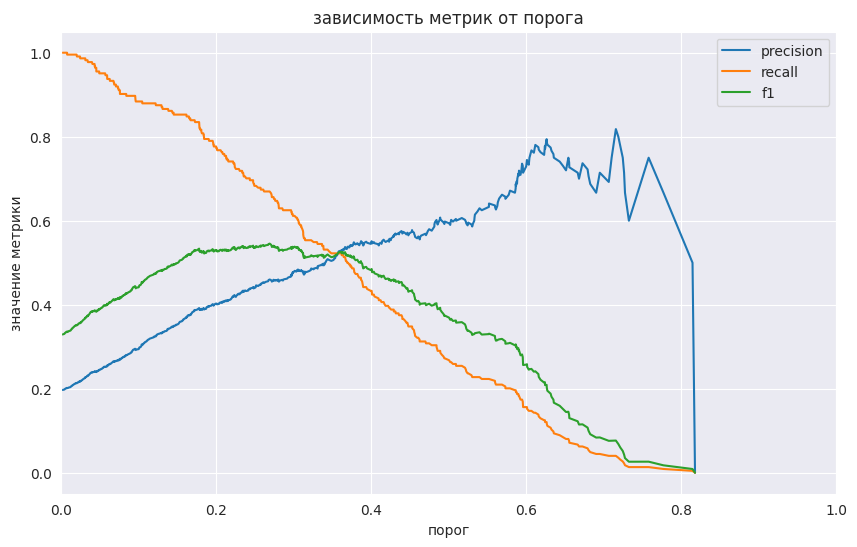

лучший порог по f1: 0.2688887270064323
f1 на валидации: 0.5454545454545454
лучший порог при recall >= 0.7: 0.24319636418160753
precision на валидации: 0.43854748603351956
recall на валидации: 0.7008928571428571


,порог,значение,precision,recall,f1
0,"0,5",0.500000,0.597561,0.255875,0.358318
1,tF1,0.268889,0.473888,0.639687,0.544444
2,tR,0.243196,0.436975,0.678851,0.531697


recall >= 0.7 на тесте: False


In [15]:
# ваше решение здесь
XFit, XVal, yFit, yVal = train_test_split(X_train, y_train, test_size=0.25, stratify=y_train, random_state=42)
pipelVal = make_pipeline(StandardScaler(), LogisticRegression())
pipelVal.fit(XFit, yFit)
pVal = pipelVal.predict_proba(XVal)[:, 1]
prec25, rec25, thres25 = metrics.precision_recall_curve(yVal, pVal)
prec25 = prec25[:-1]
rec25 = rec25[:-1]
f1sc25 = 2 * prec25 * rec25 / np.maximum(prec25 + rec25, 1e-15)
plt.figure(figsize=(10, 6))
plt.plot(thres25, prec25, label='precision')
plt.plot(thres25, rec25, label='recall')
plt.plot(thres25, f1sc25, label='f1')
plt.xlabel('порог')
plt.ylabel('значение метрики')
plt.title('зависимость метрик от порога')
plt.xlim(0, 1)
plt.legend()
plt.grid(True)
plt.show()
idxF1 = np.argmax(f1sc25)
tF1 = thres25[idxF1]
validIdx = np.where(rec25 >= 0.7)[0]
idxR = validIdx[np.argmax(prec25[validIdx])]
tR = thres25[idxR]
print(f"лучший порог по f1: {tF1}")
print(f"f1 на валидации: {f1sc25[idxF1]}")
print(f"лучший порог при recall >= 0.7: {tR}")
print(f"precision на валидации: {prec25[idxR]}")
print(f"recall на валидации: {rec25[idxR]}")
pipelFin = make_pipeline(StandardScaler(), LogisticRegression())
pipelFin.fit(X_train, y_train)
pTest = pipelFin.predict_proba(X_test)[:, 1]
res25 = []
for name, t in [('0,5', 0.5), ('tF1', tF1), ('tR', tR)]:
  yPred25 = (pTest >= t).astype(int)
  res25.append({'порог': name, 'значение': t, 'precision': metrics.precision_score(y_test, yPred25, zero_division=0), 'recall': metrics.recall_score(y_test, yPred25), 'f1': metrics.f1_score(y_test, yPred25)})

dfRes25 = pd.DataFrame(res25)
display(dfRes25)
print(f"recall >= 0.7 на тесте: {dfRes25.loc[2, 'recall'] >= 0.7}")

*Ваши выводы здесь.*

- на валидации был выбран tF1 = 0.2689, максимизирующий f1 = 0.5455, и tR = 0.2432, максимизирующий precision при recall >= 0.7

- recall >= 0.7 на тесте не выполнилось, хотя на валидации был равен 0.7009. это из за различия между выборками, а еще из за того, что после выбора порога модель была переобучена на всём треине, из за чего её предсказания могли измениться. поэтому порог, подобранный на валидации, не гарантирует выполнения условия на новых данных

- для сценария из описания данных я бы выбрал tF1 = 0.2689, тк важно как не рекомендовать посредственные вина, так и не пропускать хорошие. Этот порог обеспечивает лучший баланс по precision и recall среди рассмотренных вариантов по метрике f1

## <font color="green">Часть 3. Несбалансированные классы (2.5 балла)</font>

Класс «хорошее вино» встречается примерно в 5 раз реже остальных. На семинаре 4 мы обсуждали, что с этим можно сделать:
- задать классам веса (`class_weight='balanced'`);
- сбалансировать обучающую выборку: undersampling, oversampling и их комбинации (библиотека [imbalanced-learn](https://imbalanced-learn.org/stable/)).

Во всех заданиях этой части сравнивайте модели по одному и тому же набору метрик на тестовой выборке: accuracy, precision, recall, $F_1$ (при пороге по умолчанию), ROC-AUC и PR-AUC. Удобно написать для этого одну функцию, которая принимает обученную модель и возвращает строку таблицы.

**Важно:** ресемплинг применяется **только к тренировочной выборке**. Тестовая выборка остаётся нетронутой, иначе метрики перестанут отражать качество на реальном распределении классов.

### Задание 3.1. Веса классов (0.5 балла)

Обучите логистическую регрессию в пайплайне со `StandardScaler` с параметром `class_weight=None` и `class_weight='balanced'`. Сведите метрики двух моделей в таблицу.

1. Какие веса получают объекты классов 0 и 1 при `class_weight='balanced'`? Посчитайте их по формуле из документации `sklearn`.
2. Какие метрики заметно изменились, а какие почти нет? Объясните, почему.

In [16]:
def evalModel(name, model):
  yPre = model.predict(X_test)
  yProb = model.predict_proba(X_test)[:, 1]
  return {'модель': name, 'accuracy': metrics.accuracy_score(y_test, yPre), 'precision': metrics.precision_score(y_test, yPre, zero_division=0),
          'recall': metrics.recall_score(y_test, yPre), 'f1': metrics.f1_score(y_test, yPre), 'roc-auc': metrics.roc_auc_score(y_test, yProb), 'pr-auc': metrics.average_precision_score(y_test, yProb)}

In [17]:
# ваше решение здесь
n = len(y_train)
n0 = (y_train == 0).sum()
n1 = (y_train == 1).sum()
w0 = n / (2 * n0)
w1 = n / (2 * n1)
print(f"вес класса 0: {w0}")
print(f"вес класса 1: {w1}")
modelNone31 = make_pipeline(StandardScaler(), LogisticRegression(class_weight=None))
modelBal31 = make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced'))
modelNone31.fit(X_train, y_train)
modelBal31.fit(X_train, y_train)
res31 = [evalModel('class_weight=None', modelNone31), evalModel('class_weight=balanced', modelBal31)]
dfRes31 = pd.DataFrame(res31)
display(dfRes31)

вес класса 0: 0.622365179304681
вес класса 1: 2.5430648769574944


,модель,accuracy,precision,recall,f1,roc-auc,pr-auc
0,class_weight=None,0.820000,0.597561,0.255875,0.358318,0.813537,0.512115
1,class_weight=balanced,0.726667,0.396978,0.754569,0.520252,0.811339,0.500536


*Ваши выводы здесь.*

- при class_weight='balanced' вес класса 0 - 0.6224, а класса 1 — 2.5431, то есть ошибки на редком классе 1 учитываются примерно в 4 раза сильнее, чем ошибки той же величины на классе 0

- после балансировки recall заметно вырос с 0.2559 до 0.7546, тк модель стала уделять больше внимания хорошим винам и чаще предсказывать класс 1, а precision снизился с 0.5976 до 0.3970, а accuracy — с 0.82 до 0.7267, тк увеличилось колво ошибочных рекомендаций обычных вин (FP)

- f1 вырос с 0.3583 до 0.5203, тк значительное увеличение recall перевесило снижение precision

- roc-auc почти не изменился, как и pr-auc, тк балансировка сильно повлияла на предсказания классов при пороге 0.5, но сравнительно мало изменила ранжирование объектов по вероятностям

### Задание 3.2. Ресемплинг (1 балл)

С помощью `imblearn.pipeline.make_pipeline` соберите пайплайны логистической регрессии с разными способами балансировки:
- `RandomUnderSampler`;
- `NearMiss(version=2)`;
- `RandomOverSampler`;
- `SMOTE`.

Для каждого метода выведите размеры классов в обучающей выборке после ресемплинга и добавьте строку в таблицу метрик из задания 3.1.

Ответьте на вопросы:
- Почему здесь нужен `make_pipeline` именно из `imblearn`, а не из `sklearn`? Что произойдёт с тестовой выборкой при вызове `predict` у такого пайплайна?
- Почему нельзя сначала сбалансировать весь датасет, а уже потом разбить его на train и test?
- Какой из методов оказался лучшим по PR-AUC, а какой – худшим? Как вы думаете, почему?
- Для каких из четырёх методов важен порядок шагов «ресемплинг» и «масштабирование» в пайплайне, а для каких нет? Почему? Проверьте на одном из методов, что изменится, если поменять шаги местами.

In [18]:
from imblearn.pipeline import make_pipeline as make_imb_pipeline
from imblearn.under_sampling import RandomUnderSampler, NearMiss
from imblearn.over_sampling import RandomOverSampler, SMOTE
from collections import Counter
from sklearn.base import clone

In [19]:
# ваше решение здесь
samps = {'RandomUnderSampler': RandomUnderSampler(random_state=42), 'NearMiss': NearMiss(version=2), 'RandomOverSampler': RandomOverSampler(random_state=42), 'SMOTE': SMOTE(random_state=42)}
models32 = {}
res32 = [evalModel('class_weight=None', modelNone31), evalModel('class_weight=balanced', modelBal31)]
for name, samp in samps.items():
  model32 = make_imb_pipeline(StandardScaler(), samp, LogisticRegression())
  model32.fit(X_train, y_train)
  models32[name] = model32
  prep = make_imb_pipeline(StandardScaler(), clone(samp))
  _, yRes = prep.fit_resample(X_train, y_train)
  print(f"{name}: {Counter(yRes)}")
  res32.append(evalModel(name, model32))

dfRes32 = pd.DataFrame(res32)
display(dfRes32)
modelScale1 = make_imb_pipeline(StandardScaler(), NearMiss(version=2), LogisticRegression())
modelSamp1 = make_imb_pipeline(NearMiss(version=2), StandardScaler(), LogisticRegression())
modelScale1.fit(X_train, y_train)
modelSamp1.fit(X_train, y_train)
dfOrd = pd.DataFrame([evalModel('Scaler - NearMiss', modelScale1), evalModel('NearMiss - Scaler', modelSamp1)])
display(dfOrd)
idx1 = modelScale1.named_steps['nearmiss'].sample_indices_
idx2 = modelSamp1.named_steps['nearmiss'].sample_indices_
print(f"совпадают выбранные объекты: {np.array_equal(np.sort(idx1), np.sort(idx2))}")

RandomUnderSampler: Counter({0: 894, 1: 894})
NearMiss: Counter({0: 894, 1: 894})
RandomOverSampler: Counter({0: 3653, 1: 3653})
SMOTE: Counter({0: 3653, 1: 3653})


,модель,accuracy,precision,recall,f1,roc-auc,pr-auc
0,class_weight=None,0.820000,0.597561,0.255875,0.358318,0.813537,0.512115
1,class_weight=balanced,0.726667,0.396978,0.754569,0.520252,0.811339,0.500536
2,RandomUnderSampler,0.729744,0.401099,0.762402,0.525653,0.809354,0.500791
3,NearMiss,0.544103,0.281897,0.853786,0.423850,0.739948,0.400108
4,RandomOverSampler,0.726667,0.397260,0.757180,0.521114,0.811484,0.500225
5,SMOTE,0.729231,0.399166,0.749347,0.520871,0.812465,0.503985


,модель,accuracy,precision,recall,f1,roc-auc,pr-auc
0,Scaler - NearMiss,0.544103,0.281897,0.853786,0.423850,0.739948,0.400108
1,NearMiss - Scaler,0.681026,0.351183,0.736292,0.475548,0.755049,0.393364


совпадают выбранные объекты: False


*Ваши выводы здесь.*

- make_pipeline из imblearn нужен, тк методы ресемплинга используют fit_resample(), изменяя колво объектов и соответствующие метки классов, а обычный pipeline из sklearn не поддерживает такие промежуточные шаги. при вызове predict ресемплинг не применяется к тестовой выборке, выполняются только масштабирование и предсказание модели

- балансировать весь датасет до разделения на треин и тест нельзя из за возможной утечки данных, тк например, копии одинаковых объектов при oversampling могут попасть одновременно в треине и тесте, что приведёт к завышению оценки качества + тестовая выборка должна сохранять исходное распределение классов, чтобы метрики отражали работу модели на реальных данных

- среди 4 методов ресемплинга лучший pr-auc показал smote (0.5040), а худший показал NearMiss (0.4001). smote создаёт синтетические объекты редкого класса, не удаляя исходные данные. NearMiss удаляет значительную часть объектов преобладающего класса, из за чего обучающая выборка может хуже показывать исходное распределение, при этом лучший pr-auc остался у модели без балансировки (0.5121)

- порядок масштабирования и ресемплинга особенно важен для NearMiss и smote, тк они используют расстояния между объектами. Для RandomUnderSampler и RandomOverSampler сам выбор объектов от масштабирования не зависит, но результаты модели тоже могут измениться из за различий в параметрах стандартизации. NearMiss: при перестановке шагов accuracy выросла с 0.5441 до 0.6810, f1 — с 0.4239 до 0.4755, но recall снизился с 0.8538 до 0.7363, а pr-auc — с 0.4001 до 0.3934. проверка индексов подтвердила, что NearMiss выбрал разные наборы обучающих объектов, тк расстояния вычислялись до или после стандартизации признаков

### Задание 3.3. Веса классов или порог? (0.75 балла)

Сравните на тестовой выборке две модели:
- логистическую регрессию с `class_weight='balanced'` и порогом 0.5;
- логистическую регрессию без весов с порогом $t_{F_1}$ из задания 2.5.

Постройте их PR-кривые на одном графике и отметьте на каждой кривой точку, соответствующую выбранному порогу. Сильно ли различаются кривые? Можно ли сказать, что взвешивание классов в основном «сдвигает порог»?

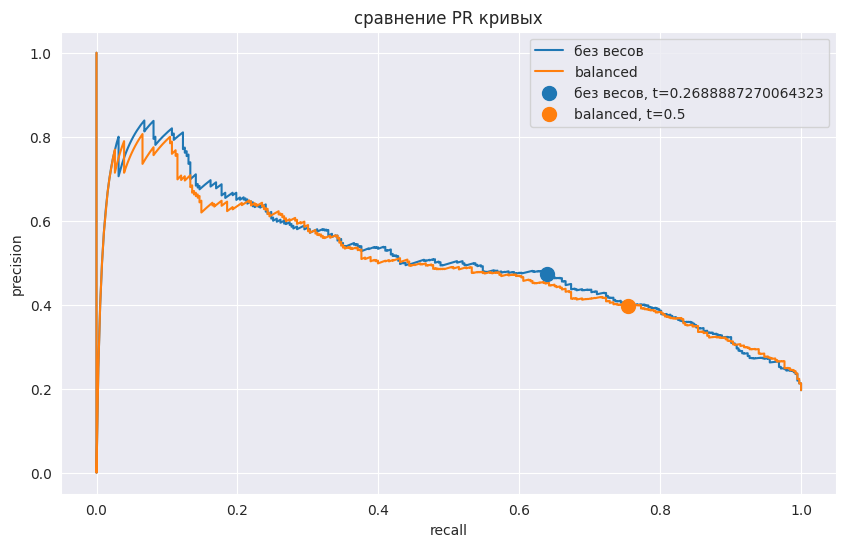

,модель,accuracy,precision,recall,f1,roc-auc,pr-auc,порог
0,без весов,0.789744,0.473888,0.639687,0.544444,0.813537,0.512115,0.268889
1,balanced,0.726667,0.396978,0.754569,0.520252,0.811339,0.500536,0.500000


In [20]:
# ваше решение здесь
pNone = modelNone31.predict_proba(X_test)[:, 1]
pBal = modelBal31.predict_proba(X_test)[:, 1]
yPredNone = (pNone >= tF1).astype(int)
yPredBal = (pBal >= 0.5).astype(int)
precNone, recNone, _ = metrics.precision_recall_curve(y_test, pNone)
precBal, recBal, _ = metrics.precision_recall_curve(y_test, pBal)
plt.figure(figsize=(10, 6))
plt.plot(recNone, precNone, label='без весов')
plt.plot(recBal, precBal, label='balanced')
precisionNone = metrics.precision_score(y_test, yPredNone)
recallNone = metrics.recall_score(y_test, yPredNone)
precisionBal = metrics.precision_score(y_test, yPredBal)
recallBal = metrics.recall_score(y_test, yPredBal)
plt.scatter(recallNone, precisionNone, s=100, label=f'без весов, t={tF1}', zorder=5)
plt.scatter(recallBal, precisionBal, s=100, label='balanced, t=0.5', zorder=5)
plt.xlabel('recall')
plt.ylabel('precision')
plt.title('сравнение PR кривых')
plt.legend()
plt.grid(True)
plt.show()
resNone = evalModel('без весов', modelNone31)
resBal = evalModel('balanced', modelBal31)
resNone['accuracy'] = metrics.accuracy_score(y_test, yPredNone)
resNone['precision'] = metrics.precision_score(y_test, yPredNone)
resNone['recall'] = metrics.recall_score(y_test, yPredNone)
resNone['f1'] = metrics.f1_score(y_test, yPredNone)
resNone['порог'] = tF1
resBal['порог'] = 0.5
dfRes33 = pd.DataFrame([resNone, resBal])
display(dfRes33)

*Ваши выводы здесь.*

PR кривые 2 моделей отличаются несильно, тк pr-auc модели без весов - 0.5121, а модели с class_weight='balanced' — 0.5005, то есть модели примерно одинаково ранжируют вина по вероятности принадлежности к классу 1

но при выбранных порогах результаты отличаются. модель без весов с порогом 0.2689 получила precision = 0.4739, recall = 0.6397 и f1 = 0.5444, а сбалансированная модель с порогом 0.5 получила precision = 0.3970, recall = 0.7546 и f1 = 0.5203. то есть, взвешивание классов по эффекту похоже на уменьшение порога, тк модель начинает чаще предсказывать класс 1, из за чего recall увеличивается, а precision снижается, но эти подходы не полностью эквивалентны. изменение порога не влияет на обученные коэффициенты и ранжирование объектов, а взвешивание меняет функцию потерь и может изменять коэффициенты модели

### Задание 3.4. Итоги (0.25 балла)

Сведите в одну таблицу все модели частей 2 и 3 (метрики на тестовой выборке). Какую модель и какой порог вы бы предложили сервису из сценария? Обоснуйте выбор, опираясь на метрики.

In [21]:
def evalThres(name, model, thres):
    res = evalModel(name, model)
    p = model.predict_proba(X_test)[:, 1]
    yPred = (p >= thres).astype(int)
    res['accuracy'] = metrics.accuracy_score(y_test, yPred)
    res['precision'] = metrics.precision_score(y_test, yPred, zero_division=0)
    res['recall'] = metrics.recall_score(y_test, yPred)
    res['f1'] = metrics.f1_score(y_test, yPred)
    res['порог'] = thres
    return res

def evalPreds(name, yPred, p):
    return {'модель': name, 'accuracy': metrics.accuracy_score(y_test, yPred), 'precision': metrics.precision_score(y_test, yPred, zero_division=0),
            'recall': metrics.recall_score(y_test, yPred), 'f1': metrics.f1_score(y_test, yPred), 'roc-auc': metrics.roc_auc_score(y_test, p), 'pr-auc': metrics.average_precision_score(y_test, p), 'порог': 0.5}

In [22]:
# ваше решение здесь
dfRes34 = dfRes32.copy()
dfRes34['порог'] = 0.5
extra = [evalThres('без весов tF1', pipelFin, tF1), evalThres('без весов tR', pipelFin, tR)]
yZero = np.zeros(len(y_test), dtype=int)
extra.append(evalPreds('константная', yZero, yZero))
pOwn = model24.predict_proba(XTestScaled24)[:, 1]
yOwn = model24.predict(XTestScaled24)
extra.append(evalPreds('своя LogReg', yOwn, pOwn))
dfRes34 = pd.concat([dfRes34, pd.DataFrame(extra)], ignore_index=True)
display(dfRes34)

,модель,accuracy,precision,recall,f1,roc-auc,pr-auc,порог
0,class_weight=None,0.820000,0.597561,0.255875,0.358318,0.813537,0.512115,0.500000
1,class_weight=balanced,0.726667,0.396978,0.754569,0.520252,0.811339,0.500536,0.500000
2,RandomUnderSampler,0.729744,0.401099,0.762402,0.525653,0.809354,0.500791,0.500000
3,NearMiss,0.544103,0.281897,0.853786,0.423850,0.739948,0.400108,0.500000
4,RandomOverSampler,0.726667,0.397260,0.757180,0.521114,0.811484,0.500225,0.500000
5,SMOTE,0.729231,0.399166,0.749347,0.520871,0.812465,0.503985,0.500000
6,без весов tF1,0.789744,0.473888,0.639687,0.544444,0.813537,0.512115,0.268889
7,без весов tR,0.765128,0.436975,0.678851,0.531697,0.813537,0.512115,0.243196
8,константная,0.803590,0.000000,0.000000,0.000000,0.500000,0.196410,0.500000
9,своя LogReg,0.821026,0.602410,0.261097,0.364299,0.813487,0.512042,0.500000


*Ваши выводы здесь.*

если условие recall >= 0.7 обязательное, то среди рассмотренных моделей я бы предложил RandomUnderSampler с порогом 0.5. у нее recall = 0.7624, precision = 0.4011 и f1 = 0.5257. я выбрал ее, тк среди вариантов, удовлетворяющих ограничению на recall на тесте, она показала наибольшие precision и f1

если ограничения на recall нет, то я бы выбрал логистическую регрессию без балансировки классов с порогом 0.2689, подобранным на валидации. у неё precision = 0.4739, recall = 0.6397 и f1 = 0.5444. эта модель показала наибольший f1, а также более высокий precision, чем модели с балансировкой, поэтому она обеспечивает лучший компромисс между колвом найденных хороших вин и долей действительно хороших вин среди рекомендованных

### Сохранение модели (0 баллов, нужно для части 4)

Сохраните итоговую модель (весь пайплайн, а не только `LogisticRegression`), выбранный порог и тестовую выборку – они понадобятся в приложении. Допишите ячейку под свою итоговую модель.

Если работаете в Colab, скачайте папку `wine_app/` на свой компьютер (например, заархивируйте её и воспользуйтесь `google.colab.files.download`): приложение запускается локально.

In [23]:
import json
import joblib
from pathlib import Path

app_dir = Path('wine_app')
app_dir.mkdir(exist_ok=True)

final_model = models32['RandomUnderSampler']      # ваш итоговый пайплайн, обученный на X_train
final_threshold = 0.5  # выбранный порог

joblib.dump(final_model, app_dir / 'model.joblib')
(app_dir / 'config.json').write_text(json.dumps({'threshold': float(final_threshold)}))
X_test.assign(target=y_test).to_csv(app_dir / 'test.csv', index=False)

In [24]:
import shutil
from google.colab import files

shutil.make_archive('wine_app', 'zip', '.', 'wine_app')
files.download('wine_app.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:
import sklearn
import imblearn
import sys

print("Python:", sys.version)
print("sklearn:", sklearn.__version__)
print("imblearn:", imblearn.__version__)
print("joblib:", joblib.__version__)

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
sklearn: 1.6.1
imblearn: 0.14.2
joblib: 1.6.0


## <font color="green">Часть 4. Демо-приложение на Streamlit (2.5 балла)</font>

Модель в ноутбуке видите только вы. Чтобы ей мог пользоваться сомелье сервиса (и чтобы он понимал, почему меняется подборка при изменении порога), сделаем небольшое веб-приложение.

[Streamlit](https://docs.streamlit.io/) это библиотека, которая которая превращает обычный Python-скрипт в веб-страницу: каждый вызов вроде `st.slider(...)` или `st.write(...)` рисует элемент интерфейса, а при любом действии пользователя скрипт перезапускается сверху вниз. Минимальный пример:

```python
import streamlit as st

t = st.slider('Порог', 0.0, 1.0, 0.5)
st.write('Вы выбрали порог', t)
```

Приложение запускается **локально**, а не в Colab:

```bash
pip install streamlit
streamlit run app.py
```

Полезные элементы: [`st.number_input`](https://docs.streamlit.io/develop/api-reference/widgets/st.number_input), [`st.slider`](https://docs.streamlit.io/develop/api-reference/widgets/st.slider), [`st.tabs`](https://docs.streamlit.io/develop/api-reference/layout/st.tabs), [`st.file_uploader`](https://docs.streamlit.io/develop/api-reference/widgets/st.file_uploader), [`st.download_button`](https://docs.streamlit.io/develop/api-reference/widgets/st.download_button), [`st.pyplot`](https://docs.streamlit.io/develop/api-reference/charts/st.pyplot), [`st.metric`](https://docs.streamlit.io/develop/api-reference/data/st.metric), [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource) (чтобы не загружать модель заново при каждом перезапуске скрипта).

Приложение `wine_app/app.py` использует файлы, сохранённые в ячейке выше (`model.joblib`, `config.json`, `test.csv`). **Модель внутри приложения не обучается.**

### Задание 4.1. Оценка одного вина (0.5 балла)

Сделайте вкладку, на которой пользователь вводит 12 признаков вина (диапазоны и значения по умолчанию возьмите из данных, например минимум, максимум и медиану по `test.csv`; признак `is_red` – переключатель «красное / белое»). Сделайте сайдбар с интерактивным ползунком значения порога, установите порог по умолчанию значением из файла `config.json`. Приложение показывает вероятность того, что вино хорошее, и решение модели при установленном пороге.

### Задание 4.2. Интерактивная визуализация модельных метрик (0.5 балла)

Сделайте вкладку «Модельные метрики». При изменении порога на тестовой выборке пересчитываются и выводятся:
- матрица ошибок;
- precision, recall и $F_1$;
- ROC- и PR-кривые, на которых отмечена точка, соответствующая текущему порогу.

Добавьте короткий текст для сомелье: что произойдёт с подборкой, если порог увеличить или уменьшить.

### Задание 4.3. Пакетное предсказание (0.5 балла)

Сделайте вкладку, на которой пользователь загружает CSV-файл с признаками вин (без столбца `target`), а приложение показывает таблицу с вероятностью и решением для каждого вина и даёт скачать её через `st.download_button`. Порог для этой вкладки берётся из слайдера задания 4.2 (подсказка: [`st.session_state`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.session_state)) или задаётся отдельно – на ваш выбор.

Приложение не должно падать, если в файле не хватает столбцов: в этом случае выведите понятное сообщение об ошибке (`st.error`).

### Задание 4.4. Что выучила модель (0.25 балла)

Сделайте вкладку с горизонтальной столбчатой диаграммой коэффициентов логистической регрессии (после масштабирования признаков), отсортированных по значению. Подпишите, какие признаки сильнее всего «голосуют» за хорошее вино, а какие – против.

### Задание 4.5. Кэширование (0.25 балла)

Streamlit выполняет `app.py` заново при каждом действии пользователя: сдвинули слайдер порога – скрипт отработал сверху вниз ещё раз. Без кэширования при каждом движении слайдера модель снова читается с диска, а вероятности на тестовой выборке пересчитываются, хотя от порога они не зависят.

1. Модель загружается функцией с декоратором [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource): один объект на весь сервер. Путь к файлу строится от папки, где лежит `app.py` (`Path(__file__).parent`), а не от текущей директории.
2. `test.csv` читается функцией с декоратором [`st.cache_data`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_data).
3. Вероятности класса 1 на тестовой выборке считаются один раз, в функции с `st.cache_data`. При движении слайдера в задании 4.2 меняется только сравнение с порогом, `predict_proba` заново не вызывается. Подсказка: аргумент, который Streamlit не должен хешировать (например, модель), называют с подчёркиванием в начале: `def test_proba(_model, X): ...`.

Ответьте в `README.md` или в комментарии в `app.py`: почему для модели используется `st.cache_resource`, а для таблиц – `st.cache_data`? Что изменится, если вызвать `joblib.load` без декоратора?

Использование `joblib.load` без декоратора или загрузка модели через `st.cache_data` за этот пункт не засчитываются.

### Задание 4.6. Оформление и сдача (0.5 балла)

1. Сдайте папку `wine_app/` (архивом или укажите в клетке ниже ссылку на Github репозиторий) со следующим содержимым:
- `app.py`;
- `model.joblib`, `config.json`, `test.csv`;
- `requirements.txt` с версиями библиотек, при которых приложение запускается;
- `README.md`: инструкция о том, как запустить приложение с указанием версии Python интерпретатора.

2. Проведите деплой приложения на [Streamlit Community Cloud](https://streamlit.io/cloud).

**Опишите общие мысли о работе. Это место для вашей рефлексии – необязательное, но полезное.** 🍷

интересно было задплоить модель, поработать со стримлит. не думал, что может быть достойный фронтенд без html, js, css... + он довольно простой